## Data Science Practicum

### Week 4

### Import libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

### Load NEISS dataset

Loading the NEISS dataset to begin the analysis of consumer product-related injuries.

In [2]:
# Loading dataset
df = pd.read_excel("E:\\NEISS2024.xlsx")

# Displaying the first few rows
df.head()

,CPSC_Case_Number,Treatment_Date,Age,Sex,Race,Other_Race,Hispanic,Body_Part,Diagnosis,Other_Diagnosis,...,Fire_Involvement,Product_1,Product_2,Product_3,Alcohol,Drug,Narrative_1,Stratum,PSU,Weight
0,240108461,2024-01-01,16,1,0,NaN,1,30,64,NaN,...,0,1267,0,0,0,0,"16YOM PLAYING SOCCER, HURT HIS SHOULDER. HIT ...",S,29,104.4634
1,240108462,2024-01-01,56,2,1,NaN,2,92,59,NaN,...,0,464,0,0,0,0,56YOF WAS CUTTING UP CABBAGE AND KNIFE SLIPPED...,S,29,104.4634
2,240109863,2024-01-01,10,1,1,NaN,2,93,54,NaN,...,0,5036,1615,0,0,0,10 YOM C/O CRUSH INJURY OF TOE S/P RIDING A DI...,C,204,7.5201
3,240109864,2024-01-01,3,2,0,NaN,2,0,41,NaN,...,0,1686,0,0,0,0,3 YOF PRESENTS WITH SWALLOWED FOREIGN BODY S/P...,C,204,7.5201
4,240109865,2024-01-01,2,1,0,NaN,1,76,59,NaN,...,0,4074,0,0,0,0,2 YOM PRESENTS WITH FACIAL LACERATION S/P FELL...,C,204,7.5201


In [3]:
# Checking available columns
df.columns.tolist()

['CPSC_Case_Number',
 'Treatment_Date',
 'Age',
 'Sex',
 'Race',
 'Other_Race',
 'Hispanic',
 'Body_Part',
 'Diagnosis',
 'Other_Diagnosis',
 'Body_Part_2',
 'Diagnosis_2',
 'Other_Diagnosis_2',
 'Disposition',
 'Location',
 'Fire_Involvement',
 'Product_1',
 'Product_2',
 'Product_3',
 'Alcohol',
 'Drug',
 'Narrative_1',
 'Stratum',
 'PSU',
 'Weight']

### 1. Data Overview

Reviewing the size, column labels and column data types to determine what information is available.

Checking structure to determine significance of variables to analyze.

In [4]:
# Checking dataset size
df.shape

(361672, 25)

In [5]:
# Viewing columns
df.columns.tolist()

['CPSC_Case_Number',
 'Treatment_Date',
 'Age',
 'Sex',
 'Race',
 'Other_Race',
 'Hispanic',
 'Body_Part',
 'Diagnosis',
 'Other_Diagnosis',
 'Body_Part_2',
 'Diagnosis_2',
 'Other_Diagnosis_2',
 'Disposition',
 'Location',
 'Fire_Involvement',
 'Product_1',
 'Product_2',
 'Product_3',
 'Alcohol',
 'Drug',
 'Narrative_1',
 'Stratum',
 'PSU',
 'Weight']

# Data types


In [6]:
# Checking data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 361672 entries, 0 to 361671
Data columns (total 25 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   CPSC_Case_Number   361672 non-null  int64         
 1   Treatment_Date     361672 non-null  datetime64[ns]
 2   Age                361672 non-null  int64         
 3   Sex                361672 non-null  int64         
 4   Race               361672 non-null  int64         
 5   Other_Race         15277 non-null   object        
 6   Hispanic           361672 non-null  int64         
 7   Body_Part          361672 non-null  int64         
 8   Diagnosis          361672 non-null  int64         
 9   Other_Diagnosis    77535 non-null   object        
 10  Body_Part_2        88551 non-null   float64       
 11  Diagnosis_2        88551 non-null   float64       
 12  Other_Diagnosis_2  22830 non-null   object        
 13  Disposition        361672 non-null  int64   

### Summary statistics

In [7]:
# Displaying the Summary Statistics
df.describe()

,CPSC_Case_Number,Treatment_Date,Age,Sex,Race,Hispanic,Body_Part,Diagnosis,Body_Part_2,Diagnosis_2,Disposition,Location,Fire_Involvement,Product_1,Product_2,Product_3,Alcohol,Drug,PSU,Weight
count,3.616720e+05,361672,361672.000000,361672.000000,361672.000000,361672.000000,361672.000000,361672.000000,88551.000000,88551.000000,361672.000000,361672.000000,361672.000000,361672.000000,361672.000000,361672.000000,361672.000000,361672.000000,361672.000000,361672.000000
mean,2.412749e+08,2024-07-05 15:46:33.346457088,47.561575,1.450859,1.210887,1.575179,64.598329,61.202866,65.320821,61.394146,1.472812,2.432837,0.011248,2189.587192,312.119113,31.325386,0.018215,0.027464,53.668205,41.664765
min,2.401085e+08,2024-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,41.000000,0.000000,41.000000,1.000000,0.000000,0.000000,106.000000,0.000000,0.000000,0.000000,0.000000,2.000000,6.580100
25%,2.405001e+08,2024-04-12 00:00:00,13.000000,1.000000,1.000000,1.000000,36.000000,57.000000,35.000000,53.000000,1.000000,0.000000,0.000000,1211.000000,0.000000,0.000000,0.000000,0.000000,21.000000,27.587000
50%,2.407884e+08,2024-07-08 00:00:00,34.000000,1.000000,1.000000,2.000000,75.000000,59.000000,76.000000,59.000000,1.000000,1.000000,0.000000,1807.000000,0.000000,0.000000,0.000000,0.000000,41.000000,27.587000
75%,2.410680e+08,2024-09-30 00:00:00,67.000000,2.000000,2.000000,2.000000,82.000000,65.000000,82.000000,71.000000,1.000000,5.000000,0.000000,3285.000000,0.000000,0.000000,0.000000,0.000000,73.000000,53.129500
max,2.503063e+08,2024-12-31 00:00:00,223.000000,2.000000,6.000000,2.000000,94.000000,74.000000,94.000000,74.000000,9.000000,9.000000,3.000000,5555.000000,5555.000000,5555.000000,1.000000,1.000000,207.000000,108.065600
std,2.194381e+06,NaN,50.063627,0.499554,0.900027,0.725550,24.003102,6.746135,22.776818,7.328551,1.200245,3.288587,0.169658,1392.884748,839.127837,274.427963,0.133730,0.163432,44.858434,29.854678


### 2. Missing Value Analysis

Identifying missing values in the dataset to evaluate data quality before performing further analysis.

The inspection of incomplete variables helps identify the field(s) that need cleaning or further processing.

In [8]:
# Calculating missing values
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().sum()/len(df))*100
})

# Sorting missing values
missing.sort_values(
    by="Missing %",
    ascending=False
).head(20)

,Missing Count,Missing %
Other_Race,346395,95.776007
Other_Diagnosis_2,338842,93.687651
Other_Diagnosis,284137,78.562067
Diagnosis_2,273121,75.516214
Body_Part_2,273121,75.516214
CPSC_Case_Number,0,0.000000
Treatment_Date,0,0.000000
Sex,0,0.000000
Age,0,0.000000
Diagnosis,0,0.000000


In [9]:
# Check duplicates
df.duplicated().sum()

np.int64(0)

#### Creating cleaned age variable

Preparing a reliable age variable for analysis by identifying invalid values in the age information.

Patients are grouped into age bands to facilitate the comparison of injury patterns in different age bands.

In [10]:
# Creating cleaned age variable
df["Age_clean"] = df["Age"]

# Removing invalid age values
df.loc[
    df["Age_clean"] > 100,
    "Age_clean"
] = np.nan

In [11]:

# Creating age groups
df["Age_group"] = pd.cut(
    df["Age_clean"],
    bins=[0,5,12,18,35,55,100],
    labels=[
        "Child (0-5)",
        "Child (6-12)",
        "Teen (13-18)",
        "Adult (19-35)",
        "Adult (36-55)",
        "Older Adult (55+)"
    ]
)

# Counting age groups
df["Age_group"].value_counts()

Age_group
Older Adult (55+)    102893
Adult (19-35)         53994
Child (6-12)          50364
Adult (36-55)         49883
Teen (13-18)          44366
Child (0-5)           37972
Name: count, dtype: int64

#### Creating Injury Severity Variable

Reviewing treatment outcome values to gain insight into categories of injury disposal.

Creating a severity indicator helps classify injuries into severe and non-severe groups for further analysis.

In [12]:
# Checking disposition values
df["Disposition"].value_counts()

# Viewing unique disposition codes
df["Disposition"].unique()

# Defining severe injury codes
severe_codes = [4,5,6]

# Creating severity variable
df["Severe_Injury"] = np.where(
    df["Disposition"].isin(severe_codes),
    1,
    0
)

# Counting severity classes
df["Severe_Injury"].value_counts()

Severe_Injury
0    312849
1     48823
Name: count, dtype: int64

### Exploratory Data Analysis

#### 1. Visualizing severe injury rate by age

Comparing injury outcomes among patient populations using severe injury rates by age groups.

Comparing the severity differences allows identification of age groups that may be at higher risk for more severe consumer product-related injuries.

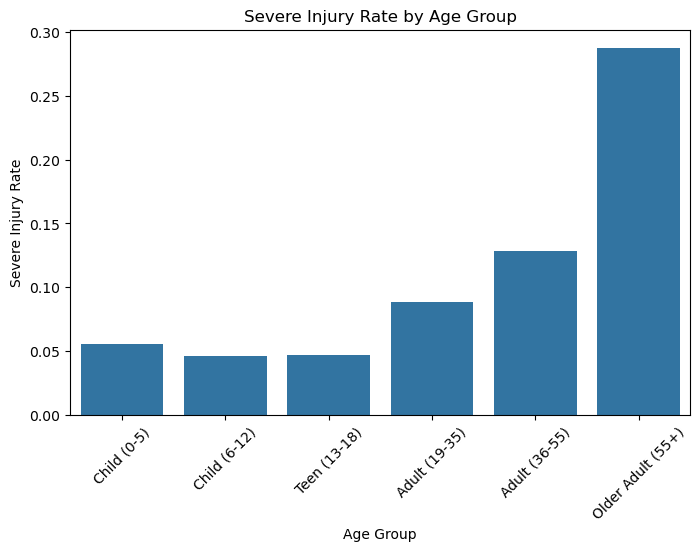

In [13]:
# Calculating severe injury rate by age group

age_severity = (
    df.groupby("Age_group")
    ["Severe_Injury"]
    .mean()
    .reset_index()
)


# Visualizing severe injury rate by age group

plt.figure(figsize=(8,5))

sns.barplot(
    data=age_severity,
    x="Age_group",
    y="Severe_Injury"
)

plt.title("Severe Injury Rate by Age Group")

plt.xlabel("Age Group")
plt.ylabel("Severe Injury Rate")

plt.xticks(rotation=45)

plt.show()

    The analysis indicates that severe injury rates are higher with age, with older adults (55+) having the highest rate of severe injuries than younger age groups. Younger groups can suffer numerous injuries that are product related, but after an injury, older adults are at a higher risk of suffering serious injuries. This implies that product safety strategies for consumers should take account of a consumer's vulnerability to age.

#### 2. Visualizing sex distribution

Sex distribution analysis of injury to gain insight into the representation of consumer product-related injury among sex categories of patients.

Sex proportions are useful for visualisation and understanding if injuries are more common in certain demographic groups.

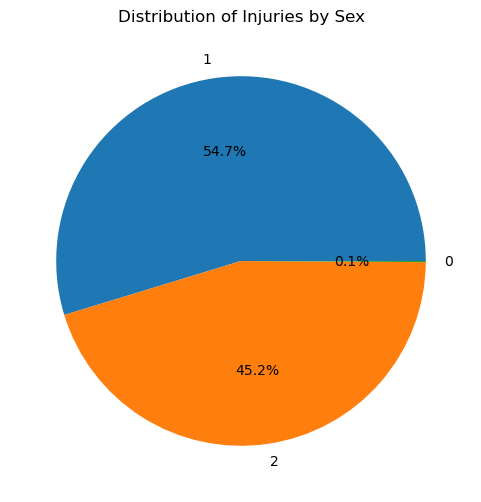

In [14]:
# Counting injuries by sex
sex_counts = df["Sex"].value_counts()


# Visualizing sex distribution
plt.figure(figsize=(6,6))
plt.pie(
    sex_counts.values,
    labels=sex_counts.index,
    autopct="%1.1f%%"
)

plt.title("Distribution of Injuries by Sex")
plt.show()

    The analysis reveals that there is a slight rate of injury among the one sex group with category 1 accounting for 54.7% and category 2 accounting for 45.2% of the cases. The difference is not very large, indicating that injuries resulting from the use of consumer products impact both groups. Sex alone may be an inadequate indicator for the occurrence of injury and must be used in conjunction with other factors, such as age, product type and severity of injury.

#### 3. Visualizing top products by injury frequency

Analyzing product frequency to identify consumer products most commonly involved in emergency department injuries.

Comparing the number of injuries reported for different products can identify products that present a greater number of injuries.

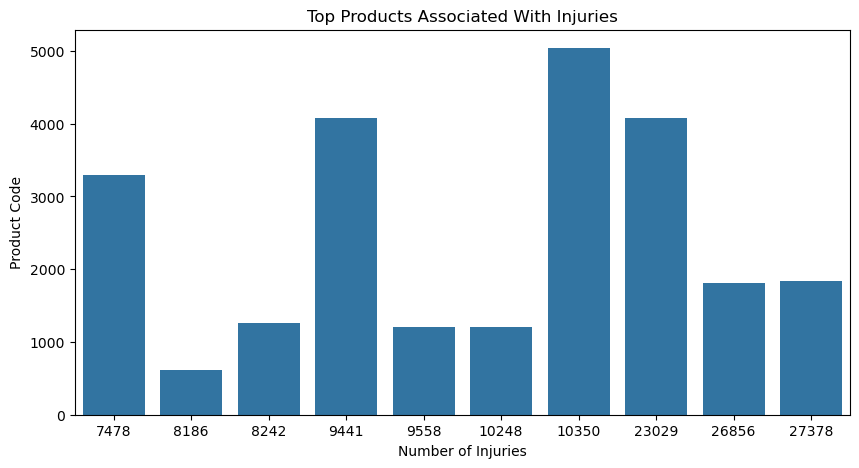

In [15]:
# Counting most common products
top_products = (
    df["Product_1"]
    .value_counts()
    .head(10)
)


# Visualizing top products

plt.figure(figsize=(10,5))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top Products Associated With Injuries")

plt.xlabel("Number of Injuries")
plt.ylabel("Product Code")

plt.show()

    The analysis reveals that some product categories have more cases of injuries in the ED than others. Products with greater numbers of injuries may reflect areas where prevention activities can have a greater overall impact. But injury frequency does not equate to injury severity, so these products need to be considered in terms of severe injuries and outcomes.

#### 4. Visualizing product severity

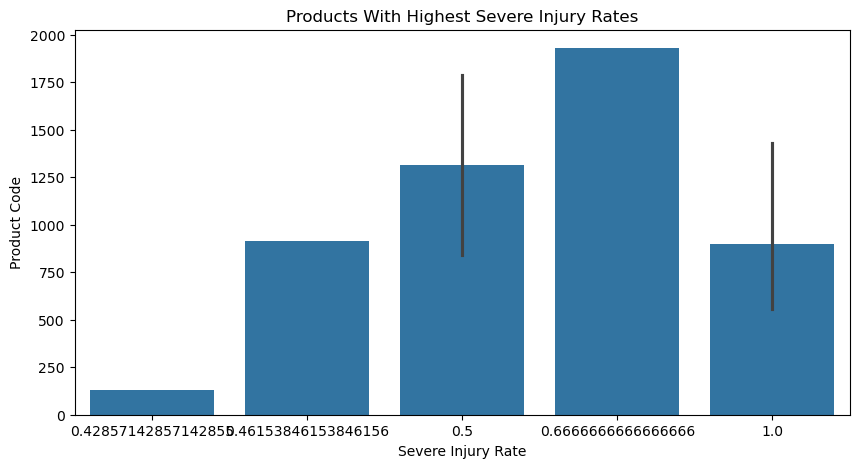

In [16]:
# Calculating severe injury rate by product
product_severity = (
    df.groupby("Product_1")
    ["Severe_Injury"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)


# Visualizing severe injury rate by product
plt.figure(figsize=(10,5))

sns.barplot(
    x=product_severity.values,
    y=product_severity.index
)

plt.title("Products With Highest Severe Injury Rates")
plt.xlabel("Severe Injury Rate")
plt.ylabel("Product Code")
plt.show()

    The analysis categorizes products with adequate injury records into the product categories that are most likely to cause severe injury. These products can be product lines where there is a higher risk of injury to result in severe consequences. Measuring injury incidence and the severity of injuries can assist CPSC in making better use of its resources to investigate safety issues.

#### 5. Injury Narrative Length Analysis

Analyzing narrative length to understand the amount of text information available in injury records.

Estimate the size of the narrative to decide if injury descriptions will be conducive to future text-based analysis.

In [17]:
# Calculating narrative length
df["Narrative_length"] = (
    df["Narrative_1"]
    .astype(str)
    .apply(len)
)

# Summarizing narrative length
df["Narrative_length"].describe()

count    361672.000000
mean        133.661464
std          69.823994
min          25.000000
25%          82.000000
50%         116.000000
75%         168.000000
max         400.000000
Name: Narrative_length, dtype: float64

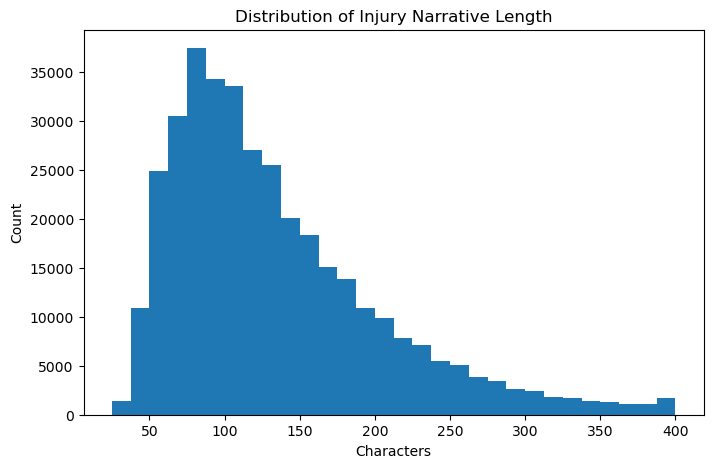

In [18]:


# Visualizing narrative length distribution
plt.figure(figsize=(8,5))

plt.hist(
    df["Narrative_length"],
    bins=30
)

plt.title(
    "Distribution of Injury Narrative Length"
)

plt.xlabel(
    "Characters"
)

plt.ylabel(
    "Count"
)

plt.show()

    Analysis indicates that the majority of injury narratives are about 50-150 characters, while a smaller number of narratives are longer. The distribution shows that NEISS narratives contain brief, but structured, descriptions of injury events. These text records can be used for future natural language processing analysis to find patterns of injuries, factors and common scenarios of consumer product injuries.

## WEEK 4

### Model Building



### Selecting Features

In [19]:
# Selecting modeling features
features = [
    "Age_clean",
    "Sex",
    "Body_Part",
    "Diagnosis",
    "Location",
    "Fire_Involvement",
    "Product_1",
    "Alcohol",
    "Drug"
]

# Creating feature dataset
X = df[features]

# Creating target variable
y = df["Severe_Injury"]

# Checking feature shape
X.shape, y.shape

((361672, 9), (361672,))

### Check target balance

In [20]:
# Checking target distribution
y.value_counts(normalize=True) * 100

Severe_Injury
0    86.500752
1    13.499248
Name: proportion, dtype: float64

In [21]:
# Filling missing age values with median age
X["Age_clean"] = X["Age_clean"].fillna(
    X["Age_clean"].median()
)

# Checking missing values again
X.isnull().sum()

Age_clean           0
Sex                 0
Body_Part           0
Diagnosis           0
Location            0
Fire_Involvement    0
Product_1           0
Alcohol             0
Drug                0
dtype: int64

In [22]:
# Checking missing values in selected features
X.isnull().sum()

Age_clean           0
Sex                 0
Body_Part           0
Diagnosis           0
Location            0
Fire_Involvement    0
Product_1           0
Alcohol             0
Drug                0
dtype: int64

### Split data

In [23]:
from sklearn.model_selection import train_test_split

# Splitting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Checking split sizes
X_train.shape, X_test.shape

((289337, 9), (72335, 9))

### Logistic Regression model

In [24]:
# Importing logistic regression model
from sklearn.linear_model import LogisticRegression

# Creating logistic regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Training the model
logistic_model.fit(
    X_train,
    y_train
)

# Predicting test data
y_pred = logistic_model.predict(
    X_test
)

# Predicting probabilities
y_prob = logistic_model.predict_proba(
    X_test
)[:,1]

### Model Performance Metrics

In [25]:
# Importing evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score)

# Calculating evaluation metrics
accuracy = accuracy_score(
    y_test,
    y_pred)

precision = precision_score(
    y_test,
    y_pred)
recall = recall_score(
    y_test,
    y_pred)

f1 = f1_score(
    y_test,
    y_pred)
roc_auc = roc_auc_score(
    y_test,
    y_prob)

# Displaying results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 0.6956107002142807
Precision: 0.2636654708174208
Recall: 0.6999487967229903
F1 Score: 0.3830419188522753
ROC-AUC: 0.7452780971333611


### Detailed Classification Report

In [26]:
# Displaying detailed classification results
from sklearn.metrics import classification_report
print(   classification_report(
        y_test,
        y_pred))

              precision    recall  f1-score   support

           0       0.94      0.69      0.80     62570
           1       0.26      0.70      0.38      9765

    accuracy                           0.70     72335
   macro avg       0.60      0.70      0.59     72335
weighted avg       0.85      0.70      0.74     72335



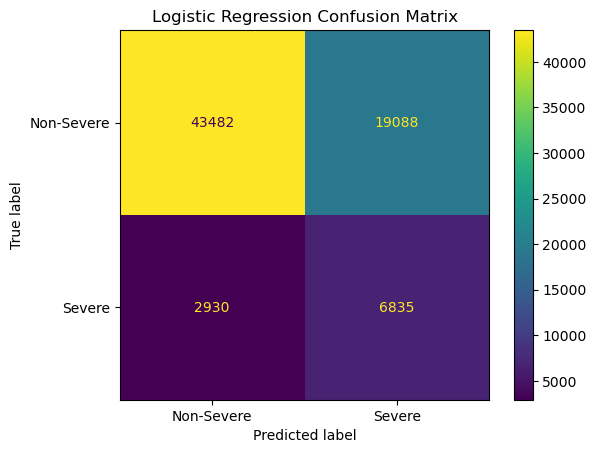

In [27]:
# Creating confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

# Plotting confusion matrix
disp = ConfusionMatrixDisplay(cm, display_labels=["Non-Severe","Severe"])

disp.plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

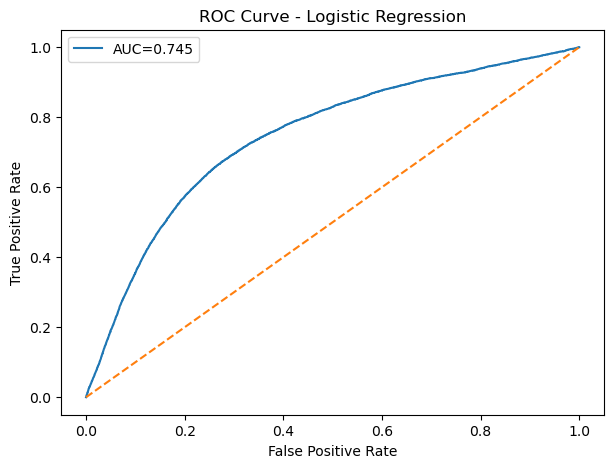

In [28]:
# Importing ROC functions
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc_score = roc_auc_score(y_test, y_prob)

# Plotting ROC curve
plt.figure(figsize=(7,5))

plt.plot(fpr, tpr, label=f"AUC={auc_score:.3f}")

plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Logistic Regression")

plt.legend()

plt.show()

### Random Forest Model

In [29]:
# Importing random forest model
from sklearn.ensemble import RandomForestClassifier

# Creating random forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Training random forest model
rf_model.fit(
    X_train,
    y_train
)

# Predicting test data
rf_pred = rf_model.predict(
    X_test
)

# Predicting probabilities
rf_prob = rf_model.predict_proba(
    X_test
)[:,1]

In [30]:
# Calculating random forest metrics
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred
)

rf_recall = recall_score(
    y_test,
    rf_pred
)

rf_f1 = f1_score(
    y_test,
    rf_pred
)

rf_auc = roc_auc_score(
    y_test,
    rf_prob
)

# Displaying random forest results

print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)
print("ROC-AUC:", rf_auc)

Accuracy: 0.8423584710029722
Precision: 0.40762463343108507
Recall: 0.3700972862263185
F1 Score: 0.38795555794106595
ROC-AUC: 0.7676409790210592


Random Forest showed better overall results in terms of accuracy (0.696 to 0.842) and ROC-AUC (0.745 to 0.768). This means that Random Forest was able to grasp more complex relationships among injury characteristics and product related variables.

However, Logistic Regression achieved higher recall (0.700 compared with 0.370), meaning it identified more severe injury cases. Missed severe injury may be more serious, therefore, the detection of severe injury is important, as the project is concentrating on severe injury prediction.

Random Forest improved the precision (0.408 vs 0.264), and slightly improved the F1-score (0.388 vs 0.383), but it was also able to detect less severe cases than Logistic Regression.

### WEEK 5

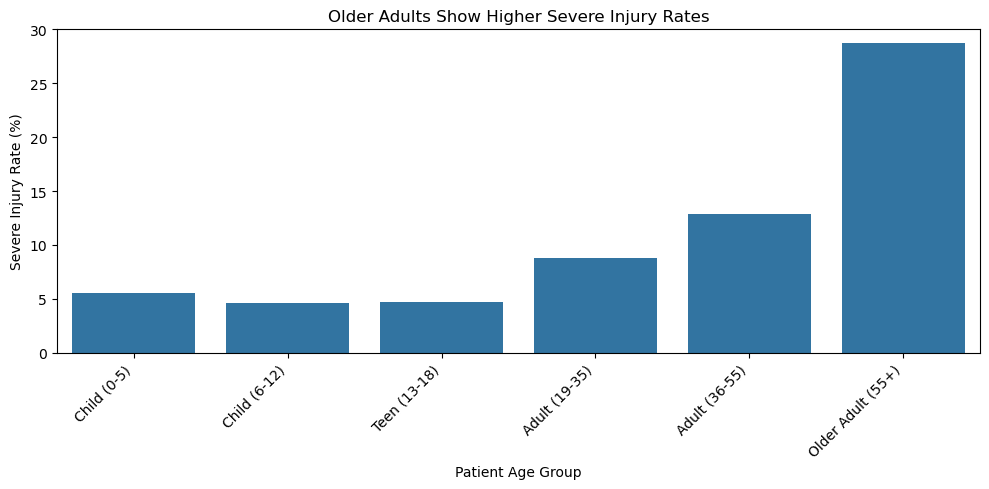

In [31]:
# Calculating severe injury rate by age group
age_severity = (
    df.groupby("Age_group")["Severe_Injury"]
    .mean()
    .reset_index()
)

# Converting severe injury rate to percentage
age_severity["Severe_Injury_Rate"] = (
    age_severity["Severe_Injury"] * 100
)

# Setting the correct age-group order
age_order = [
    "Child (0-5)",
    "Child (6-12)",
    "Teen (13-18)",
    "Adult (19-35)",
    "Adult (36-55)",
    "Older Adult (55+)"
]

# Converting Age_group to an ordered categorical variable
age_severity["Age_group"] = pd.Categorical(
    age_severity["Age_group"],
    categories=age_order,
    ordered=True
)

# Sorting age groups from youngest to oldest
age_severity = age_severity.sort_values("Age_group")


# Creating the redesigned chart
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_severity,
    x="Age_group",
    y="Severe_Injury_Rate"
)

# Adding a finding-focused headline
plt.title(
    "Older Adults Show Higher Severe Injury Rates"
)

# Labeling the x-axis and y-axis
plt.xlabel("Patient Age Group")
plt.ylabel("Severe Injury Rate (%)")

# Setting the y-axis to start at zero
plt.ylim(0, 30)

# Rotating the age-group labels for readability
plt.xticks(rotation=45, ha="right")

# Adjusting the layout
plt.tight_layout()

# Displaying the redesigned chart
plt.show()